In [ ]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

NOTEBOOK_FILE = globals().get("__vsc_ipynb_file__")
WORKSPACE_FOLDER = Path(NOTEBOOK_FILE).resolve().parents[1] if NOTEBOOK_FILE else Path.cwd()
sys.path.insert(0, str(WORKSPACE_FOLDER))

from evaluation import calc_key_figures, plot_key_figures

PRICES = pl.read_csv(WORKSPACE_FOLDER / "example_prices.csv", try_parse_dates=True).rename({"dates": "AsOfDate"})
DATE_COL = "AsOfDate"
INSTRUMENTS = [c for c in PRICES.columns if c != DATE_COL]

### Plotting price movements

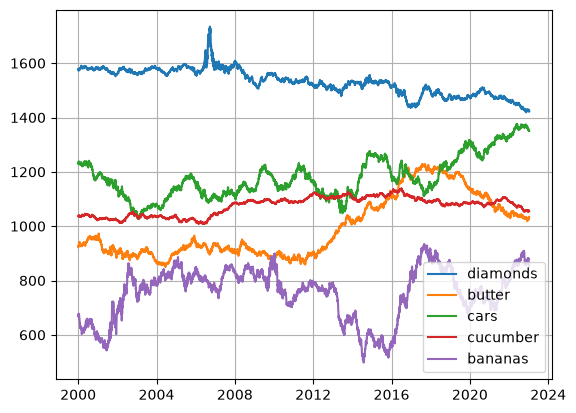

In [ ]:
fig, ax = plt.subplots()
for c in INSTRUMENTS:
    ax.plot(PRICES[DATE_COL].to_numpy(), PRICES[c].to_numpy(), label=c)
ax.legend()
ax.grid()

### Calculating normalized returns

The returns are defined as the daily price movements of assets $r_{T, j} = P_{T, j} - P_{T-1, j}$

We forecast the volatility/variance at time $T$ using $\sigma_T = \sqrt{\frac{1}{100} \sum\limits_{k= T - 100}^{T-1}{r^2_k}}$.

The normalized returns are the risk-adjusted returns using the forecasted volatility: $z_T = \frac{r_T}{\sigma_T}$.

If forecasted volatility is correct, we would expect $\sigma_z$ to be close to 1. Why? Consider:

$$\sigma_z^2 = Var\left[\frac{r_T}{\sigma_T}\right] = Var\left[\frac{r_T}{\sigma^{\text{true}}_T}\right] = E\left[\left(\frac{r_T}{\sigma^{\text{true}}_T} - E\left[\frac{r_T}{\sigma^{\text{true}}_T}\right]\right)^2\right] = \frac{Var(r_T)}{(\sigma^{\text{true}}_T)^2} = \frac{(\sigma^{\text{true}}_T)^2}{(\sigma^{\text{true}}_T)^2} = 1$$

As seen below this is true for our data. If $\sigma_z^2$ were much greater than 1, however, it would suggest that actual returns were larger than the volatility forecast implied. This could be caused by volatility jumps that the rolling window is too slow to capture, by fat-tailed returns, or by errors in the price data.

shape: (1, 5)
┌──────────┬─────────┬──────────┬──────────┬──────────┐
│ diamonds ┆ butter  ┆ cars     ┆ cucumber ┆ bananas  │
│ ---      ┆ ---     ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64     ┆ f64      ┆ f64      ┆ f64      │
╞══════════╪═════════╪══════════╪══════════╪══════════╡
│ 1.022204 ┆ 1.01673 ┆ 1.020913 ┆ 1.015677 ┆ 1.024953 │
└──────────┴─────────┴──────────┴──────────┴──────────┘


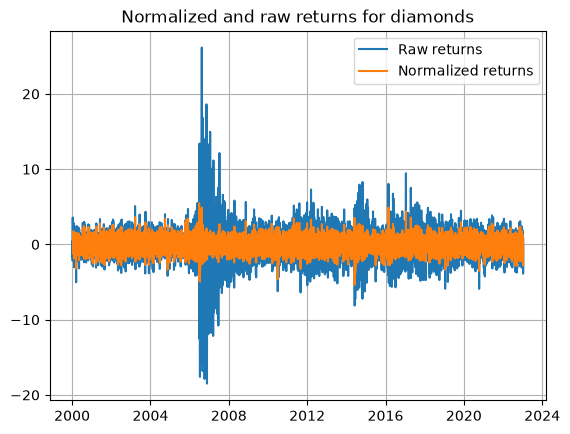

In [20]:
RETURNS = PRICES.select(DATE_COL, pl.col(INSTRUMENTS).diff())
VOL = RETURNS.select(DATE_COL, pl.col(INSTRUMENTS).pow(2).rolling_mean(100, min_samples=10).sqrt().shift(1))
RETURNS_NORM = RETURNS.select(DATE_COL, *[(pl.col(c) / VOL[c]).fill_nan(None).alias(c) for c in INSTRUMENTS])
print(RETURNS_NORM.select(pl.col(INSTRUMENTS).std()))

instrument_0 = INSTRUMENTS[0]
fig, ax = plt.subplots()
ax.title.set_text(f"Normalized and raw returns for {instrument_0}")
ax.plot(RETURNS[DATE_COL].to_numpy(), RETURNS[instrument_0].to_numpy(), label="Raw returns")
ax.plot(RETURNS_NORM[DATE_COL].to_numpy(), RETURNS_NORM[instrument_0].to_numpy(), label="Normalized returns")
ax.legend()
ax.grid()

### Correlation between different assets

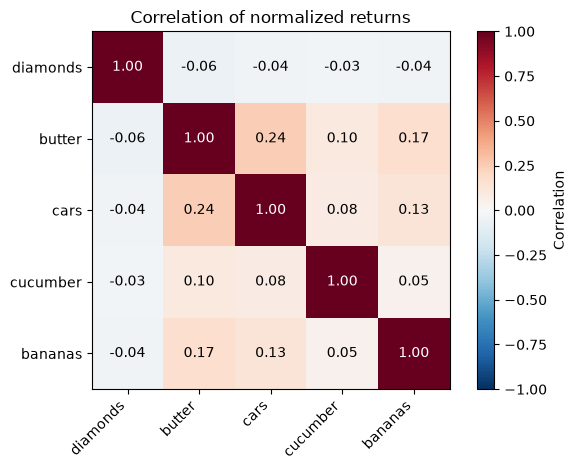

In [22]:
corr = RETURNS_NORM.select(INSTRUMENTS).drop_nulls().corr().to_numpy()

fig, ax = plt.subplots()
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(INSTRUMENTS)), INSTRUMENTS, rotation=45, ha="right")
ax.set_yticks(range(len(INSTRUMENTS)), INSTRUMENTS)
for i in range(len(INSTRUMENTS)):
    for j in range(len(INSTRUMENTS)):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(corr[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation of normalized returns")
fig.tight_layout()


### Normalized return distributions

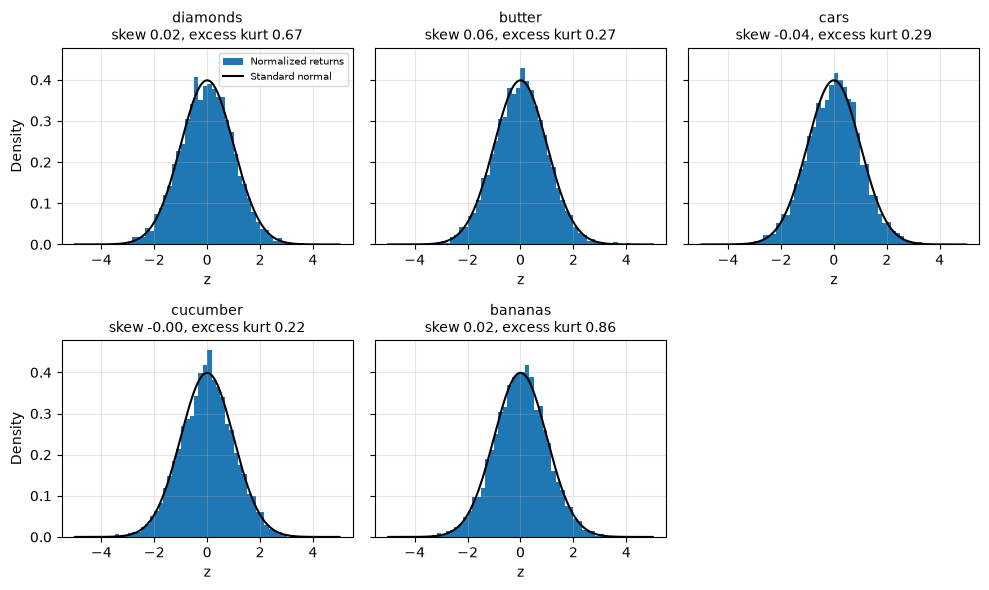

In [26]:
bins = np.linspace(-5, 5, 61)
x = np.linspace(-5, 5, 300)
normal_pdf = np.exp(-x**2 / 2) / np.sqrt(2 * np.pi)

fig, axes = plt.subplots(2, 3, figsize=(10, 6), sharex=True, sharey=True)
axes = axes.flatten()
for ax, c in zip(axes, INSTRUMENTS):
    z = RETURNS_NORM[c].drop_nulls()
    ax.hist(z.to_numpy(), bins=bins, density=True, label="Normalized returns")
    ax.plot(x, normal_pdf, color="black", linewidth=1.5, label="Standard normal")
    ax.set_title(f"{c}\nskew {z.skew():.2f}, excess kurt {z.kurtosis():.2f}", fontsize=10)
    ax.set_xlabel("z")
    ax.tick_params(labelbottom=True)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Density")
axes[3].set_ylabel("Density")
axes[0].legend(fontsize=7)
axes[5].axis("off")
fig.tight_layout()
